# Analytical analysis of the model

This notebook examines the onset of oscillations in a barrel-cortex model adapted from [Pinto et al. (1996)](https://doi.org/10.1007/BF00161134), with and without refractoriness.

**Both versions undergo a supercritical Hopf bifurcation.** The small cycle starts near 32 Hz with refractoriness and 34 Hz without it. At larger input, the cycle frequency differs from the local eigenvalue frequency; removing refractoriness changes these values but does not eliminate oscillations.

The calculations below establish the local Hopf and verify sampled periodic orbits. They do not prove that every sampled orbit belongs to one globally connected branch.

The notebook is self-contained and requires NumPy, SciPy and Matplotlib. No datasets, caches or external scripts are loaded. Time is in milliseconds; the full cycle calculations may take several minutes.

## 1. Model and parameters

The state variables $E$ and $I$ are excitatory and inhibitory synaptic drives. The input $T$ is a constant, already filtered thalamic drive:

$$
\begin{aligned}
\tau_e\dot E&=-E+A_e(E)P_e(V_e),\\[5pt]
\tau_i\dot I&=-I+A_i(I)P_i(V_i),
\end{aligned}
$$

where

$$
\begin{aligned}
V_e&=42E-24I+46.8T, & A_e(E)&=\gamma_e[1-r_eP_e(E)],\\[5pt]
V_i&=42E-18I+15T, & A_i(I)&=\gamma_i[1-r_iP_i(I)].
\end{aligned}
$$

The response functions are

$$
P_x(v)=\frac12\left[1+\operatorname{erf}\left(\frac{v-15}{\Theta_x}\right)\right].
$$

Here $r_e,r_i$ denote the refractory parameters called `er, ir` in the original implementation; $\Theta_x$ denotes sigmoid temperature, not thalamic input. The offset is $15=\theta-\rho$, with $\theta=-45$ mV and $\rho=-60$ mV.

| Parameter | Value |
|:---|:---|
| Synaptic time constants $(\tau_e,\tau_i)$ | $(5,15)$ ms |
| Scale factors $(\gamma_e,\gamma_i)$ | $(5,15)$ |
| Sigmoid temperatures $(\Theta_e,\Theta_i)$ | $(12.03,11.62)$ |
| Refractory parameters $(r_e,r_i)$ | $(2.2,4.1)$, or $(0,0)$ without refractoriness |
| Convergences $(ec,ic,tc_e,tc_i)$ | $(42,12,12,10)$ |
| Weights $(w_{ee},w_{ei},w_{ie},w_{ii},w_{te},w_{ti})$ | $(1,1,2,1.5,3.9,1.5)$ |

The modified parameters are $w_{ti}=1.5$ and $r_e=2.2$, versus 6 and 7.4 in the reference model. The voltage coefficients above already include convergence factors. Removing refractoriness means setting both refractory parameters to zero, with no refitting. The original thalamic filter is not integrated here; for constant forcing it adds a stable eigenvalue $-1/\tau_e$ without changing the cortical Hopf condition.

In [1]:
from pathlib import Path
import numpy as np
from scipy.special import erf
from scipy.optimize import root, brentq
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

# Modified parameter set; time is in milliseconds.
tau = np.array([5., 15.])
gamma = np.array([5., 15.])
refractory = np.array([2.2, 4.1])
temperature = np.array([12.03, 11.62])
W = np.array([[42., -24.], [42., -18.]])
thalamic_weights = np.array([46.8, 15.])

def activation(v):
    z = (v - 15.) / temperature
    return (1. + erf(z)) / 2.

def activation_derivatives(v):
    z = (v - 15.) / temperature
    p0 = activation(v)
    p1 = np.exp(-z*z) / (np.sqrt(np.pi) * temperature)
    p2 = -2*z*p1 / temperature
    p3 = (4*z*z - 2)*p1 / temperature**2
    return p0, p1, p2, p3

def field(x, T, refractory_parameters=None):
    parameters = refractory if refractory_parameters is None else np.asarray(refractory_parameters)
    voltage = W @ x + thalamic_weights*T
    available = gamma*(1 - parameters*activation(x))
    return (-x + available*activation(voltage))/tau

def derivatives(x, T):
    p = activation_derivatives(W @ x + thalamic_weights*T)
    s = activation_derivatives(x)
    a = [gamma*(1 - refractory*s[0])]
    for order in range(1,4):
        a.append(-gamma*refractory*s[order])
    J = np.zeros((2,2))
    B = np.zeros((2,2,2))
    C = np.zeros((2,2,2,2))
    for i in range(2):
        for j in range(2):
            dj = float(i == j)
            J[i,j] = (a[0][i]*p[1][i]*W[i,j] + a[1][i]*dj*p[0][i] - dj)/tau[i]
            for k in range(2):
                dk = float(i == k)
                B[i,j,k] = (a[0][i]*p[2][i]*W[i,j]*W[i,k]
                    + a[1][i]*p[1][i]*(dj*W[i,k] + dk*W[i,j])
                    + a[2][i]*p[0][i]*dj*dk)/tau[i]
                for l in range(2):
                    dl = float(i == l)
                    C[i,j,k,l] = (a[0][i]*p[3][i]*W[i,j]*W[i,k]*W[i,l]
                        + a[1][i]*p[2][i]*(dj*W[i,k]*W[i,l] + dk*W[i,j]*W[i,l] + dl*W[i,j]*W[i,k])
                        + a[2][i]*p[1][i]*(dj*dk*W[i,l] + dj*dl*W[i,k] + dk*dl*W[i,j])
                        + a[3][i]*p[0][i]*dj*dk*dl)/tau[i]
    return J, B, C

def equilibrium(T, guess=(.2,.5)):
    result = root(lambda x: field(x,T), guess, tol=1e-11)
    if np.max(np.abs(field(result.x,T))) > 1e-9:
        raise RuntimeError('Equilibrium did not converge')
    return result.x

def trace_at(T):
    return np.trace(derivatives(equilibrium(T),T)[0])


import matplotlib.pyplot as plt


## 2. Phase-plane overview

The streamplots show the main change directly: at low input, trajectories approach a stable focus; above the Hopf threshold, they approach a cycle around an unstable equilibrium. Both versions show this behaviour, although their cycle frequencies differ.

Grey arrows show the flow, red and blue curves are the nullclines, and black curves are periodic trajectories. A filled point marks a stable equilibrium; a cross marks an unstable one. **The axes differ between panels.** These introductory trajectories are obtained by integration; the later calculations refine the cycles with shooting.


In [2]:
# Early overview; later sections refine the periodic orbits with shooting.
preview_portraits = []
for use_ref in [True, False]:
    parameters = np.array([2.2, 4.1]) if use_ref else np.zeros(2)
    for T in [.08, .12, .20]:
        def preview_rhs(t, x):
            return field(x, T, parameters)

        result = root(lambda x: preview_rhs(0, x), [.2, .5], tol=1e-11)
        x = result.x
        assert np.max(np.abs(preview_rhs(0, x))) < 1e-9
        h = 1e-6
        J = np.column_stack([
            (preview_rhs(0, x + h*np.eye(2)[k])
             - preview_rhs(0, x - h*np.eye(2)[k])) / (2*h)
            for k in range(2)
        ])
        eigenvalues = np.linalg.eigvals(J)
        cycle = None
        if eigenvalues.real.max() > 0:
            times = np.arange(1500., 2500., .1)
            solution = solve_ivp(preview_rhs, (0, 2500), x + [.04, 0.],
                                 t_eval=times, rtol=2e-9, atol=1e-11)
            assert solution.success
            peaks, _ = find_peaks(solution.y[0],
                                 prominence=.1*np.ptp(solution.y[0]))
            assert len(peaks) >= 3
            start, stop = peaks[-2:]
            period = np.mean(np.diff(times[peaks]))
            orbit = solution.y[:, start:stop+1]
            cycle = {'orbit': orbit, 'time': times[start:stop+1]-times[start],
                     'frequency': 1000/period}
            low = orbit.min(axis=1)
            high = orbit.max(axis=1)
            span = high-low
            low = np.maximum(0, low-.22*span)
            high = high+.22*span
        else:
            low = np.maximum(0, x-[.13, .24])
            high = x+[.15, .27]

        eg, ig = np.meshgrid(np.linspace(low[0], high[0], 100),
                             np.linspace(low[1], high[1], 100))
        vectors = np.array([
            preview_rhs(0, point)
            for point in np.column_stack([eg.ravel(), ig.ravel()])
        ]).T.reshape(2, *eg.shape)
        preview_portraits.append({
            'refractory': use_ref, 'T': T, 'equilibrium': x,
            'eigenvalues': eigenvalues, 'cycle': cycle,
            'Egrid': eg, 'Igrid': ig, 'field': vectors,
        })


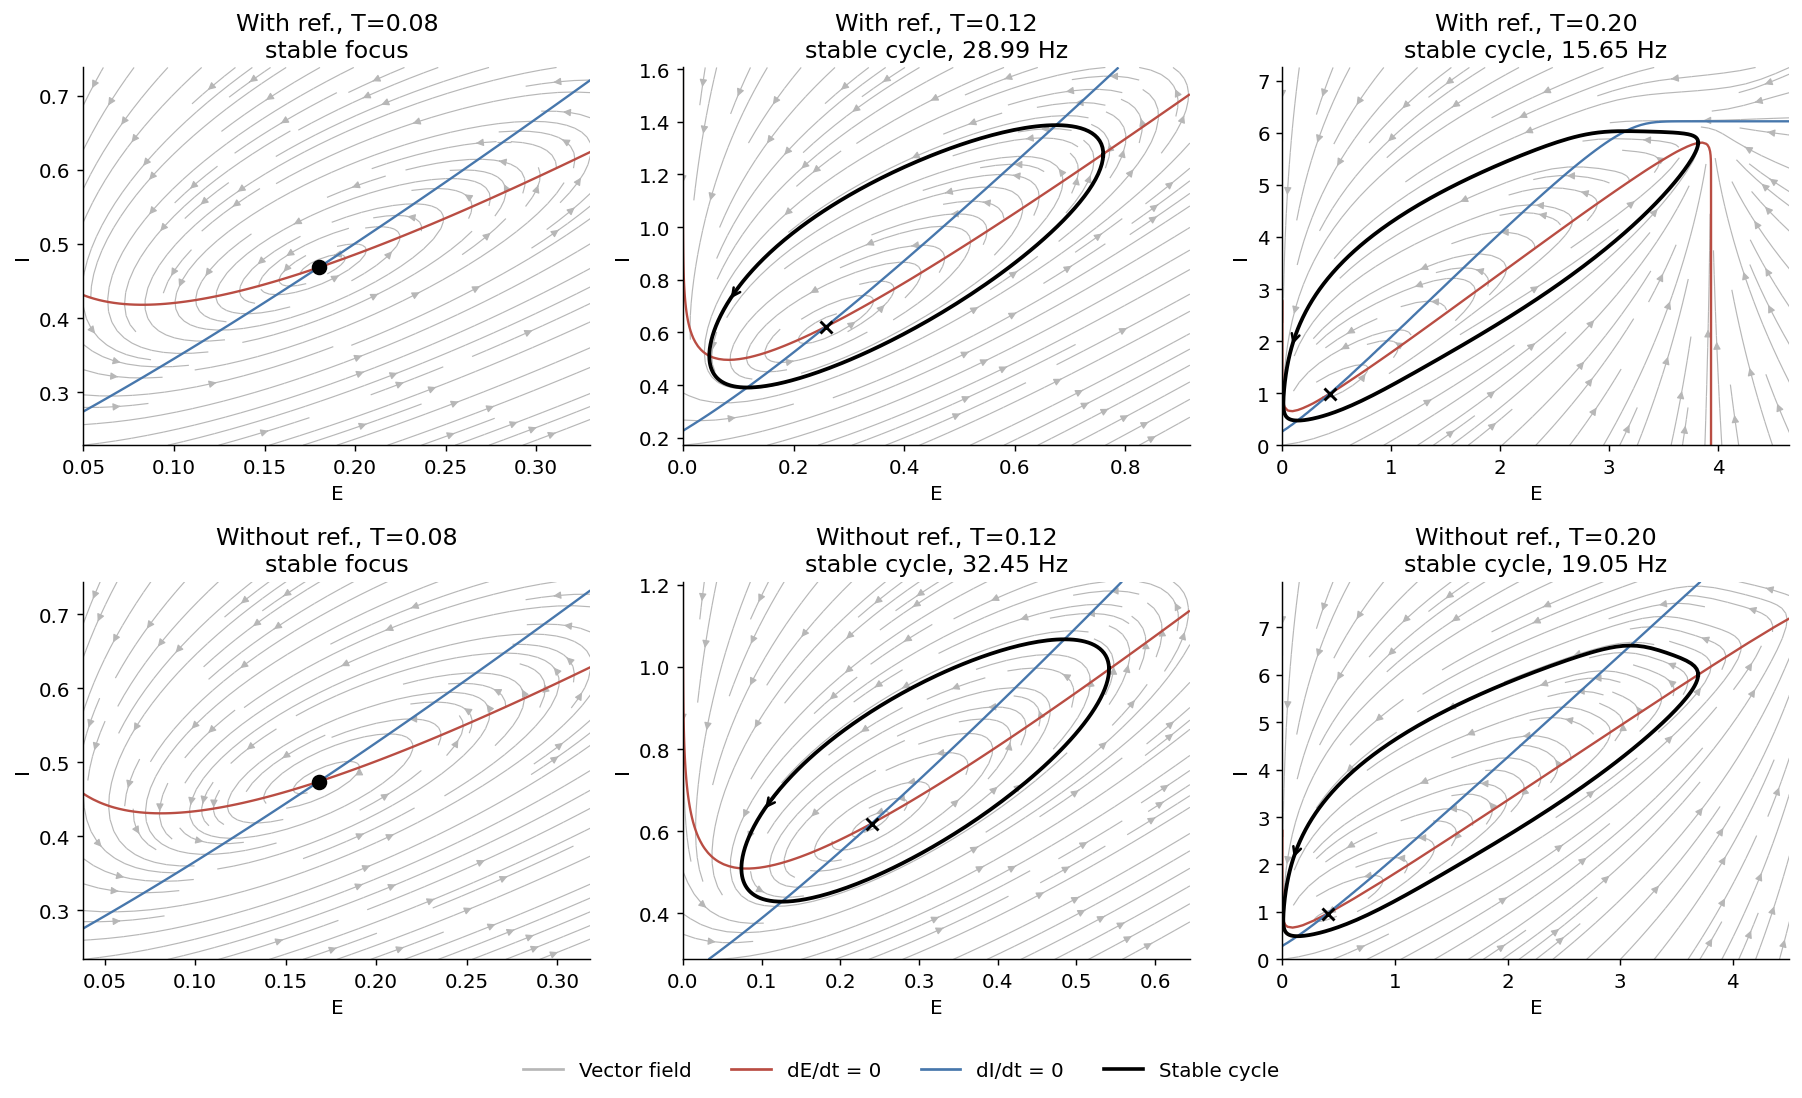

In [3]:
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
from matplotlib.lines import Line2D
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for axis, portrait in zip(axes.flat, preview_portraits):
    eg = portrait['Egrid']
    ig = portrait['Igrid']
    f = portrait['field']
    axis.streamplot(eg[0], ig[:,0], f[0], f[1], color='#b7b7b7', density=1.05, linewidth=.65, arrowsize=.85, zorder=1)
    axis.contour(eg, ig, f[0], levels=[0], colors=['#b94d43'], linewidths=1.3)
    axis.contour(eg, ig, f[1], levels=[0], colors=['#4777ac'], linewidths=1.3)
    x = portrait['equilibrium']
    stable = portrait['eigenvalues'].real.max() < 0
    axis.plot(x[0], x[1], 'o' if stable else 'x', color='black', ms=7, mew=1.6, zorder=5)
    cycle = portrait['cycle']
    if cycle is not None:
        orbit = cycle['orbit']
        axis.plot(orbit[0], orbit[1], color='black', lw=2.1, zorder=4)
        j = len(cycle['time'])//3
        axis.annotate('', xy=orbit[:,j+15], xytext=orbit[:,j], arrowprops=dict(arrowstyle='->', color='black', lw=1.4))
        subtitle = f"stable cycle, {cycle['frequency']:.2f} Hz"
    else:
        subtitle = 'stable focus'
    label = 'With ref.' if portrait['refractory'] else 'Without ref.'
    axis.set(xlabel='E', ylabel='I', title=f"{label}, T={portrait['T']:.2f}\n{subtitle}", xlim=(eg.min(),eg.max()), ylim=(ig.min(),ig.max()))
handles=[Line2D([0],[0],color='#b7b7b7',label='Vector field'),
         Line2D([0],[0],color='#b94d43',label='dE/dt = 0'),
         Line2D([0],[0],color='#4777ac',label='dI/dt = 0'),
         Line2D([0],[0],color='black',lw=2,label='Stable cycle')]
fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False)
fig.tight_layout(rect=(0,.05,1,1))
plt.show()


## 3. Equilibria and analytic eigenvalues

For each input, solve $\dot E=\dot I=0$. Write $V_e=aE-bI+u_e$ and $V_i=cE-dI+u_i$, with $(a,b,c,d)=(42,24,42,18)$. The response-function derivative is

$$
P'_x(v)=\frac{\exp[-((v-15)/\Theta_x)^2]}{\sqrt{\pi}\,\Theta_x}.
$$

To linearize, write $x=x_*+\delta x$, where $x=(E,I)^\mathsf{T}$ and $F(x_*,T)=0$. Taylor expansion gives

$$
\delta\dot x=J(x_*,T)\,\delta x+O(\|\delta x\|^2).
$$

For example, the product and chain rules give

$$
\begin{aligned}
\partial_E[A_e(E)P_e(V_e)]
&=A'_e(E)P_e(V_e)+aA_e(E)P'_e(V_e),\\[5pt]
\partial_I[A_e(E)P_e(V_e)]
&=-bA_e(E)P'_e(V_e).
\end{aligned}
$$

Since $A'_e=-\gamma_er_eP'_e(E)$ and $A'_i=-\gamma_ir_iP'_i(I)$, the product and chain rules give

$$
\begin{aligned}
J_{EE}&=\frac{-1+A'_e(E)P_e(V_e)+aA_e(E)P'_e(V_e)}{\tau_e},\\[7pt]
J_{EI}&=-\frac{bA_e(E)P'_e(V_e)}{\tau_e},\\[7pt]
J_{IE}&=\frac{cA_i(I)P'_i(V_i)}{\tau_i},\\[7pt]
J_{II}&=\frac{-1+A'_i(I)P_i(V_i)-dA_i(I)P'_i(V_i)}{\tau_i}.
\end{aligned}
$$

All entries are evaluated at the equilibrium. If $t=\operatorname{tr}J$ and $D=\det J$, then

$$
\det(\lambda\mathbb{I}-J)=(\lambda-J_{EE})(\lambda-J_{II})-J_{EI}J_{IE}
=\lambda^2-t\lambda+D,
\qquad
\boxed{\lambda_\pm=\frac{t\pm\sqrt{t^2-4D}}{2}}.
$$

For complex eigenvalues $\lambda_\pm=\sigma\pm i\omega$, the local frequency is

$$
\sigma=\frac{t}{2},\qquad
\omega=\frac{\sqrt{4D-t^2}}{2},\qquad
f_{\mathrm{eig}}=\frac{1000|\omega|}{2\pi}\;\mathrm{Hz}.
$$

Negative $\sigma$ gives damped oscillations towards the equilibrium; positive $\sigma$ gives a spiral away from it. This frequency concerns infinitesimal perturbations, not a finite-amplitude limit cycle. The eigenvalue formula is analytic; equilibrium coordinates are obtained numerically because the fixed-point equations contain erf functions.

## 4. Local Hopf bifurcation

A Hopf point requires $t=0$, $D>0$, a nonzero crossing speed and a nonzero first Lyapunov coefficient. We compute the latter using the convention

$$
f(x)=Jx+\frac12B(x,x)+\frac16C(x,x,x)+\cdots,
\qquad \langle p,q\rangle=1.
$$

The **first Lyapunov coefficient** $l_1$ classifies the local bifurcation; it is not a trajectory Lyapunov exponent. Its numerical magnitude depends on normalization, while its sign is the relevant classification here. Second- and third-order derivatives are checked against finite differences. An independent planar normal-form calculation checks the sign.

At the critical input, choose right and left eigenvectors satisfying

$$
J_Hq=i\omega_Hq,\qquad J_H^{\mathsf T}p=-i\omega_Hp,
\qquad \overline p^{\mathsf T}q=1,\qquad \|q\|_2=1.
$$

The bilinear and trilinear forms B and C contain the second and third derivatives of the vector field. The coefficient evaluated in the code is

$$
\begin{aligned}
G_{21}=\Big\langle p,\;&C(q,q,\overline q)
-2B\!\left(q,J_H^{-1}B(q,\overline q)\right)\\
&+B\!\left(\overline q,(2i\omega_H\mathbb{I}-J_H)^{-1}B(q,q)\right)\Big\rangle,
\end{aligned}
$$

$$
l_1=\frac{\operatorname{Re}G_{21}}{2\omega_H}.
$$

With $\mu=\operatorname{Re}\lambda(T)$, the local radial and phase equations have the form

$$
\begin{aligned}
\dot R&=\mu R+\ell R^3+\cdots,\\[4pt]
\dot\phi&=\omega_H+cR^2+\cdots.
\end{aligned}
$$

Here R is oscillation amplitude, not a refractory parameter; $\ell$ has the sign of $l_1$ in the chosen orientation. Since $d\mu/dT>0$ and $l_1<0$ in both cases, a small stable orbit is born on the $T>T_H$ side. The phase equation explains why finite-amplitude frequency need not equal onset frequency. This local expansion is not used to predict the large-cycle period at T=0.2–0.3.


In [4]:
T_hopf = brentq(trace_at,.04,.12,xtol=1e-13)
x_hopf = equilibrium(T_hopf)
J_hopf, B_hopf, C_hopf = derivatives(x_hopf,T_hopf)
values, vectors = np.linalg.eig(J_hopf)
index = np.argmax(values.imag)
omega = values[index].imag
q = vectors[:,index]
left_values, left_vectors = np.linalg.eig(J_hopf.T)
p = left_vectors[:,np.argmin(abs(left_values + 1j*omega))]
p = p / np.conj(np.vdot(p,q))

def Bform(u,v):
    return np.einsum('ijk,j,k->i',B_hopf,u,v)

def Cform(u,v,w):
    return np.einsum('ijkl,j,k,l->i',C_hopf,u,v,w)

# Kuznetsov convention: f(x)=Ax+B(x,x)/2+C(x,x,x)/6+...
G21 = np.vdot(p, Cform(q,q,q.conj())
    - 2*Bform(q,np.linalg.solve(J_hopf,Bform(q,q.conj())))
    + Bform(q.conj(),np.linalg.solve(2j*omega*np.eye(2)-J_hopf,Bform(q,q))))
l1 = G21.real/(2*omega)
crossing = (trace_at(T_hopf+1e-6)-trace_at(T_hopf-1e-6))/(4e-6)
print(f'T_H = {T_hopf:.10f}; equilibrium = {x_hopf}')
print(f'frequency at Hopf = {1000*omega/(2*np.pi):.5f} Hz')
print(f'd Re(lambda)/dT = {crossing:.8f}; first Lyapunov coefficient = {l1:.8f}')
print('Supercritical Hopf' if l1 < 0 and crossing > 0 else 'Check Hopf classification')

# Check analytic derivatives by differentiating lower-order tensors.
for h in [1e-4, 1e-5]:
    B_check = np.zeros_like(B_hopf)
    C_check = np.zeros_like(C_hopf)
    for k in range(2):
        dx = np.eye(2)[k]*h
        jp,bp,_ = derivatives(x_hopf+dx,T_hopf)
        jm,bm,_ = derivatives(x_hopf-dx,T_hopf)
        B_check[:,:,k] = (jp-jm)/(2*h)
        C_check[:,:,:,k] = (bp-bm)/(2*h)
    print(f'h={h:g}: B error={np.max(abs(B_check-B_hopf)):.3g}; C error={np.max(abs(C_check-C_hopf)):.3g}')



T_H = 0.0957691278; equilibrium = [0.20928498 0.52516342]
frequency at Hopf = 32.12730 Hz
d Re(lambda)/dT = 1.11423349; first Lyapunov coefficient = -2.67223281
Supercritical Hopf
h=0.0001: B error=2.71e-08; C error=2.61e-06
h=1e-05: B error=2.67e-10; C error=2.62e-08


In [5]:
M=np.column_stack([q.real,-q.imag])
Minv=np.linalg.inv(M)
Bt=np.einsum('ia,abc,bj,ck->ijk',Minv,B_hopf,M,M)
Ct=np.einsum('ia,abcd,bj,ck,dl->ijkl',Minv,C_hopf,M,M,M)
fxx,fxy,fyy=Bt[0,0,0],Bt[0,0,1],Bt[0,1,1]
gxx,gxy,gyy=Bt[1,0,0],Bt[1,0,1],Bt[1,1,1]
planar=(Ct[0,0,0,0]+Ct[0,0,1,1]+Ct[1,0,0,1]+Ct[1,1,1,1])/16+(fxy*(fxx+fyy)-gxy*(gxx+gyy)-fxx*gxx+fyy*gyy)/(16*omega)
print('Independent planar cubic coefficient:',planar)
print('Linear rotation:',Minv@J_hopf@M)


Independent planar cubic coefficient: -0.1348553975543501
Linear rotation: [[0, -0.20186175], [0.20186175, 0]]


## 5. Periodic orbits with refractoriness

**The Hopf is supercritical:** at $T_H=0.0957691$, the equilibrium loses stability and a small stable cycle appears. Its onset frequency is 32.1273 Hz.

We locate cycles by integration and refine them with shooting, enforcing

$$
\Phi_{\mathcal T}(x_0)=x_0,
$$

with $\dot E(x_0)=0$ fixing the phase. Each orbit initializes the next input value. This samples attracting cycles; it is not pseudo-arclength continuation and does not prove global branch connectivity.


In [6]:
# Numerical continuation of the attracting cycle, using the preceding orbit.
T_values = np.array([T_hopf+.0002, .0965,.098,.1,.105,.11,.12,.14,.16,.18,.2,.25,.3])
cycles = []
state = x_hopf + np.array([.03,0.])
for T in T_values:
    growth = max(np.linalg.eigvals(derivatives(equilibrium(T),T)[0]).real)
    settling = max(3500., 18/max(growth,1e-5))
    sol = solve_ivp(lambda t,x: field(x,T), (0,settling),state,rtol=2e-9,atol=1e-11)
    state = sol.y[:,-1]
    times = np.arange(0,2000.,.1)
    sol = solve_ivp(lambda t,x: field(x,T),(0,2000.),state,t_eval=times,rtol=2e-9,atol=1e-11)
    signal = sol.y[0]
    peaks,_ = find_peaks(signal,prominence=.1*np.ptp(signal))
    if len(peaks)<3:
        raise RuntimeError(f'No resolved cycle at T={T}')
    period = np.mean(np.diff(times[peaks]))
    start,stop = peaks[-2],peaks[-1]
    orbit_time = times[start:stop+1]-times[start]
    orbit = sol.y[:,start:stop+1]
    eig = np.linalg.eigvals(derivatives(equilibrium(T),T)[0])
    divergence = np.array([np.trace(derivatives(x,T)[0]) for x in orbit.T])
    floquet_log = np.trapz(divergence,orbit_time)
    cycles.append(dict(T=float(T),period=float(period),frequency=1000/period,
        amplitude=float(np.ptp(signal)),minimum=float(signal.min()),maximum=float(signal.max()),
        eigen_frequency=float(max(abs(eig.imag))*1000/(2*np.pi)),
        floquet_log=float(floquet_log),time=orbit_time,orbit=orbit))
    state = sol.y[:,-1]
    print(f'T={T:.6f}: cycle={1000/period:.4f} Hz; peak-to-peak={np.ptp(signal):.5f}; log transverse multiplier={floquet_log:.5f}',flush=True)


# Refine the rapid amplitude transition and close the orbits.
state=next(c for c in cycles if c['T']==.14)['orbit'][:,0]
for T in np.arange(.142,.160,.002):
    sol=solve_ivp(lambda t,x:field(x,T),(0,5000),state,rtol=2e-9,atol=1e-11)
    state=sol.y[:,-1]
    times=np.arange(0,1000,.1)
    sol=solve_ivp(lambda t,x:field(x,T),(0,1000),state,t_eval=times,rtol=2e-9,atol=1e-11)
    peaks,_=find_peaks(sol.y[0],prominence=.1*np.ptp(sol.y[0]))
    a,b=peaks[-2:]
    orbit=sol.y[:,a:b+1]
    tt=times[a:b+1]-times[a]
    period=np.mean(np.diff(times[peaks]))
    eig=np.linalg.eigvals(derivatives(equilibrium(T),T)[0])
    logmu=np.trapz([np.trace(derivatives(x,T)[0]) for x in orbit.T],tt)
    cycles.append(dict(T=float(T),period=float(period),frequency=1000/period,amplitude=float(np.ptp(sol.y[0])),minimum=float(sol.y[0].min()),maximum=float(sol.y[0].max()),eigen_frequency=float(max(abs(eig.imag))*1000/(2*np.pi)),floquet_log=float(logmu),time=tt,orbit=orbit))
    print('refine',T,1000/period,np.ptp(sol.y[0]),flush=True)

# Shooting at a maximum of E fixes the arbitrary phase.
for c in cycles:
    T=c['T']
    def residual(z):
        sol=solve_ivp(lambda t,x:field(x,T),(0,z[2]),z[:2],rtol=2e-10,atol=1e-12)
        return np.r_[sol.y[:,-1]-z[:2],field(z[:2],T)[0]]
    initial=np.r_[c['orbit'][:,0],c['period']]
    result=root(residual,initial,tol=1e-9)
    if np.max(abs(residual(result.x)))>1e-7 or result.x[2]<10:
        raise RuntimeError(f'Shooting failed at {T}')
    period=result.x[2]
    tt=np.linspace(0,period,1001)
    sol=solve_ivp(lambda t,x:field(x,T),(0,period),result.x[:2],t_eval=tt,rtol=2e-10,atol=1e-12)
    orbit=sol.y
    c.update(period=float(period),frequency=1000/period,amplitude=float(np.ptp(orbit[0])),minimum=float(orbit[0].min()),maximum=float(orbit[0].max()),time=tt,orbit=orbit,closure_error=float(np.max(abs(residual(result.x)[:2]))))
    c['floquet_log']=float(np.trapz([np.trace(derivatives(x,T)[0]) for x in orbit.T],tt))
    print(f"shooting T={T:.6f}: f={c['frequency']:.6f}, closure={c['closure_error']:.2g}, logmu={c['floquet_log']:.5f}",flush=True)
cycles.sort(key=lambda c:c['T'])


In [7]:
print('T        f_cycle[Hz]   peak-to-peak E   log(m_perp)   closure error')
for c in cycles:
    print(f"{c['T']:.6f}  {c['frequency']:11.5f}  {c['amplitude']:14.6f}  {c['floquet_log']:12.6f}  {c['closure_error']:.2g}")

T        f_cycle[Hz]   peak-to-peak E   log(m_perp)   closure error
0.095969     32.10326        0.051056     -0.013873  7.3e-15
0.096500     32.03931        0.098057     -0.050696  8.8e-14
0.098000     31.85749        0.173609     -0.154661  1e-13
0.100000     31.61252        0.243436     -0.292780  2.7e-14
0.105000     30.98822        0.376719     -0.632137  5.6e-13
0.110000     30.34694        0.491102     -0.956071  6e-13
0.120000     28.99495        0.712228     -1.526548  2.3e-14
0.140000     25.33708        1.311063     -2.148520  3.6e-15
0.142000     24.73425        1.416232     -2.134777  1.1e-15
0.144000     23.98610        1.551638     -2.080285  6e-12
0.146000     22.95112        1.750609     -1.943339  6.7e-15
0.148000     21.00793        2.174809     -1.542544  4.7e-14
0.150000     15.85349        3.590013     -4.129097  1e-13
0.152000     15.49859        3.687631     -6.072505  2.4e-12
0.154000     15.42276        3.715805     -6.910685  8.1e-12
0.156000     15.39805    

In [8]:
Ts=np.linspace(0,.3,301)
xs=[]; evs=[]
for T in Ts:
    x=equilibrium(T)
    xs.append(x); evs.append(np.linalg.eigvals(derivatives(x,T)[0]))
arrays=dict(Ts=Ts,equilibria=np.array(xs),eigenvalues=np.array(evs))
for k,(T,xlim,ylim) in enumerate([(.1,(0,.5),(.3,.9)),(.2,(0,4.1),(0,6.5))]):
    eg,ig=np.meshgrid(np.linspace(*xlim,220),np.linspace(*ylim,220))
    f=np.array([field(x,T) for x in np.column_stack([eg.ravel(),ig.ravel()])]).T.reshape(2,*eg.shape)
    arrays['E'+str(k)]=eg;arrays['I'+str(k)]=ig;arrays['F'+str(k)]=f


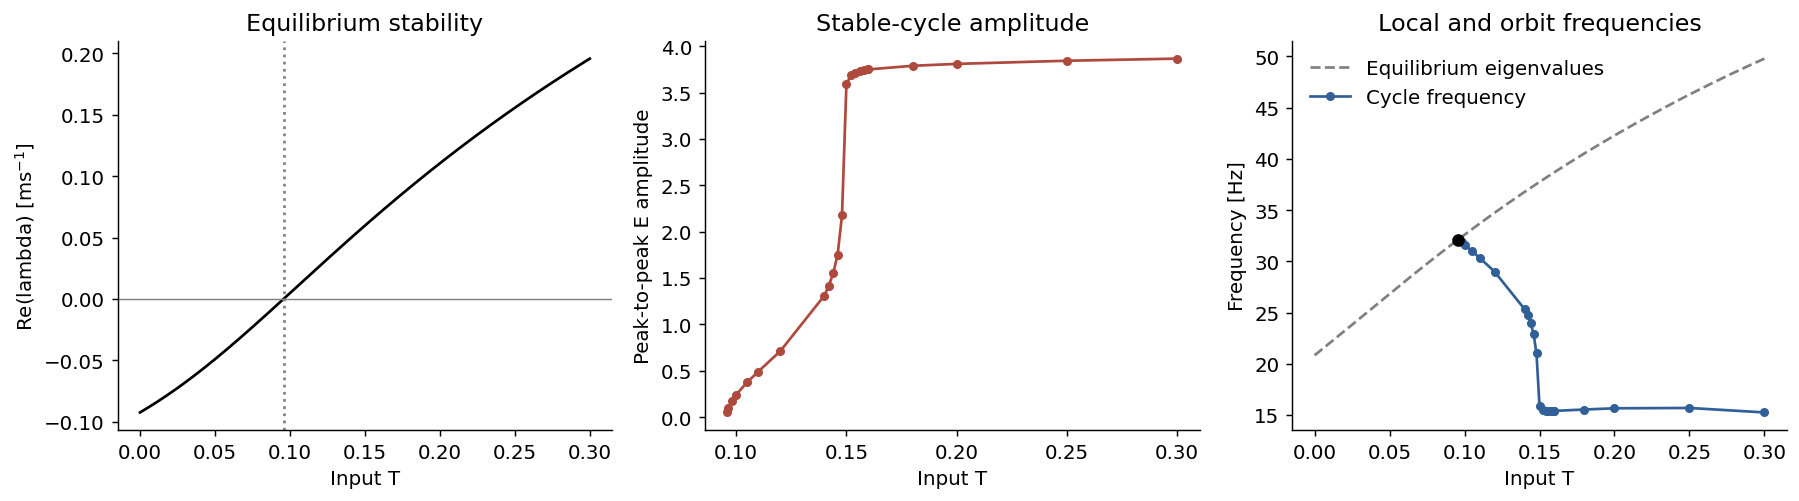

In [9]:
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
fig,ax=plt.subplots(1,3,figsize=(14,4))
t=np.array([c['T'] for c in cycles])
freq=np.array([c['frequency'] for c in cycles])
ax[0].plot(Ts,eigenvalues.real.max(axis=1),color='black')
ax[0].axhline(0,color='grey',lw=.8)
ax[0].axvline(T_hopf,color='grey',ls=':')
ax[0].set(xlabel='Input T',ylabel='Re(lambda) [ms$^{-1}$]',title='Equilibrium stability')
ax[1].plot(t,[c['amplitude'] for c in cycles],'o-',color='#ae493d',ms=4)
ax[1].set(xlabel='Input T',ylabel='Peak-to-peak E amplitude',title='Stable-cycle amplitude')
ax[2].plot(Ts,np.abs(eigenvalues.imag).max(axis=1)*1000/(2*np.pi),'--',color='grey',label='Equilibrium eigenvalues')
ax[2].plot(t,freq,'o-',color='#315f98',ms=4,label='Cycle frequency')
ax[2].scatter([T_hopf],[1000*omega/(2*np.pi)],color='black',zorder=4)
ax[2].set(xlabel='Input T',ylabel='Frequency [Hz]',title='Local and orbit frequencies')
ax[2].legend(frameon=False)
fig.tight_layout()
plt.show()


### Geometry and waveform

**The cycle slows as its amplitude grows.** Near the Hopf it stays close to the equilibrium; at larger input, excitation rises, recruits inhibition and falls, then recovers as inhibition decays. The waveform becomes a pulse followed by recovery.

This explains why a finite cycle can oscillate near 15 Hz even when the equilibrium eigenvalues imply a higher local frequency. It does not by itself establish a canard mechanism.


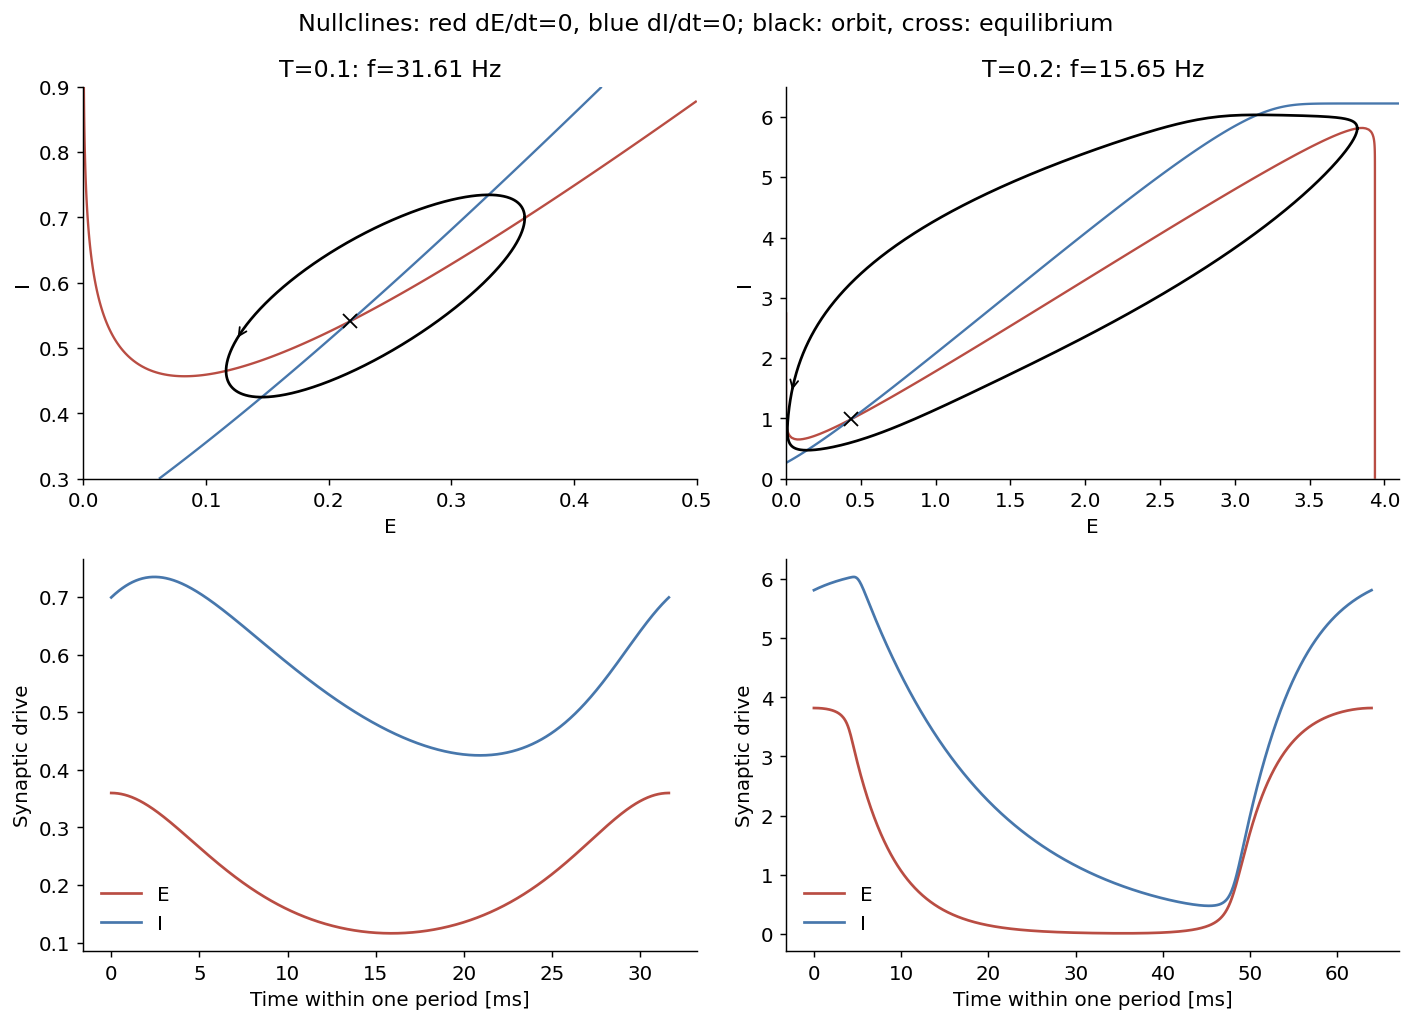

In [10]:
fig,ax=plt.subplots(2,2,figsize=(11,8))
for k,T in enumerate([.1,.2]):
    c=min(cycles,key=lambda c:abs(c['T']-T))
    orbit=c['orbit']; tt=c['time']
    eg=arrays['E'+str(k)]; ig=arrays['I'+str(k)]; ff=arrays['F'+str(k)]
    axis=ax[0,k]
    axis.contour(eg,ig,ff[0],levels=[0],colors=['#b94d43'],linewidths=1.3)
    axis.contour(eg,ig,ff[1],levels=[0],colors=['#4777ac'],linewidths=1.3)
    axis.plot(orbit[0],orbit[1],color='black',lw=1.5)
    j=int(len(tt)*.4)
    axis.annotate('',xy=orbit[:,j+12],xytext=orbit[:,j],arrowprops=dict(arrowstyle='->',color='black'))
    # Equilibrium coordinates are calculated in the preceding cell.
    idx=np.argmin(abs(Ts-T))
    axis.plot(equilibria[idx,0],equilibria[idx,1],'x',color='black',ms=8)
    axis.set(xlabel='E',ylabel='I',title=f'T={T}: f={c["frequency"]:.2f} Hz',xlim=(eg.min(),eg.max()),ylim=(ig.min(),ig.max()))
    ax[1,k].plot(tt,orbit[0],color='#b94d43',label='E')
    ax[1,k].plot(tt,orbit[1],color='#4777ac',label='I')
    ax[1,k].set(xlabel='Time within one period [ms]',ylabel='Synaptic drive')
    ax[1,k].legend(frameon=False)
fig.suptitle('Nullclines: red dE/dt=0, blue dI/dt=0; black: orbit, cross: equilibrium')
fig.tight_layout()
plt.show()


## 6. Removing refractoriness

Both refractory parameters are set to zero; all other parameters are unchanged. The equilibrium is recalculated in each case. Refractoriness changes the Jacobian directly and also shifts the operating point, so it cannot be interpreted solely as extra damping.

Without refractoriness, writing $g_e=P'_e(V_{e,*})$ and $g_i=P'_i(V_{i,*})$ gives

$$
J_0=\begin{pmatrix}
\dfrac{-1+210g_e}{5}&-\dfrac{120g_e}{5}\\[7pt]
\dfrac{630g_i}{15}&\dfrac{-1-270g_i}{15}
\end{pmatrix},
$$

and therefore

$$
\begin{aligned}
t_0&=-\frac{4}{15}+42g_e-18g_i,\\[5pt]
D_0&=\frac{1-210g_e+270g_i+18900g_eg_i}{75}.
\end{aligned}
$$

The same quadratic eigenvalue formula applies. The crossing moves to $T_H=0.1049526$, with onset frequency 34.1104 Hz. At $T=0.10$, the equilibrium is unstable with refractoriness but stable without it.

In [11]:
import numpy as np
from scipy.special import erf
from scipy.optimize import root, brentq

tau_cmp = np.array([5., 15.])
gamma_cmp = np.array([5., 15.])
temperature_cmp = np.array([12.03, 11.62])
W_cmp = np.array([[42., -24.], [42., -18.]])
thalamic_cmp = np.array([46.8, 15.])
rho_cmp = np.array([2.2, 4.1])

def p_cmp(v):
    return (1 + erf((v - 15.) / temperature_cmp)) / 2

def dp_cmp(v):
    return np.exp(-((v - 15.) / temperature_cmp)**2) / (np.sqrt(np.pi)*temperature_cmp)

def field_cmp(x, T, use_refractory=True):
    rho = rho_cmp if use_refractory else np.zeros(2)
    v = W_cmp @ x + thalamic_cmp*T
    return (-x + gamma_cmp*(1-rho*p_cmp(x))*p_cmp(v))/tau_cmp

def jac_cmp(x, T, use_refractory=True):
    rho = rho_cmp if use_refractory else np.zeros(2)
    v = W_cmp @ x + thalamic_cmp*T
    A = gamma_cmp*(1-rho*p_cmp(x))
    dA = -gamma_cmp*rho*dp_cmp(x)
    J = A[:,None]*dp_cmp(v)[:,None]*W_cmp
    J += np.diag(-1+dA*p_cmp(v))
    return J/tau_cmp[:,None]

def eq_cmp(T, use_refractory, guess=(.2,.5)):
    result = root(lambda x:field_cmp(x,T,use_refractory),guess,tol=1e-11)
    if np.max(abs(field_cmp(result.x,T,use_refractory)))>1e-9:
        raise RuntimeError('Equilibrium residual too large')
    return result.x

def eigen_formula(J):
    trace = np.trace(J)
    determinant = np.linalg.det(J)
    discriminant = trace**2-4*determinant
    radical = np.sqrt(complex(discriminant))
    return np.array([(trace+radical)/2,(trace-radical)/2])

comparison_rows = []
comparison_hopf = []
comparison_curves = []
print('Refractory   T      E*         I*         eigenvalues [ms^-1]              f_local [Hz]')
for use_refractory in [True,False]:
    for T in [0.,.04,.1,.2,.3]:
        x=eq_cmp(T,use_refractory)
        J=jac_cmp(x,T,use_refractory)
        eig=eigen_formula(J)
        numerical=np.linalg.eigvals(J).astype(complex)
        assert min(np.max(abs(eig-numerical)),np.max(abs(eig-numerical[::-1])))<1e-10
        h=1e-6
        J_fd=np.column_stack([(field_cmp(x+np.eye(2)[k]*h,T,use_refractory)-field_cmp(x-np.eye(2)[k]*h,T,use_refractory))/(2*h) for k in range(2)])
        assert np.max(abs(J-J_fd))<1e-7
        f=max(abs(eig.imag))*1000/(2*np.pi)
        comparison_rows.append(dict(refractory=use_refractory,T=T,equilibrium=x,J=J,eigenvalues=eig,frequency=f))
        print(f'{str(use_refractory):10s} {T:.2f} {x[0]:10.6f} {x[1]:10.6f} {eig[0].real:+.7f} +/- {abs(eig[0].imag):.7f}i   {f:.5f}')
    def tr(T):
        return np.trace(jac_cmp(eq_cmp(T,use_refractory),T,use_refractory))
    th=brentq(tr,0,.2,xtol=1e-13)
    xh=eq_cmp(th,use_refractory)
    Jh=jac_cmp(xh,th,use_refractory)
    fh=abs(eigen_formula(Jh)[0].imag)*1000/(2*np.pi)
    comparison_hopf.append(dict(refractory=use_refractory,T=th,frequency=fh))
    print(f'Imaginary-axis crossing: refractory={use_refractory}, T={th:.10f}, f={fh:.6f} Hz')
    tt=np.linspace(0,.3,301)
    ee=[]
    xx=[]
    for T in tt:
        x=eq_cmp(T,use_refractory)
        ee.append(eigen_formula(jac_cmp(x,T,use_refractory)))
        xx.append(x)
    comparison_curves.append(dict(refractory=use_refractory,T=tt,eigenvalues=np.array(ee),equilibria=np.array(xx)))

# Search for other physical equilibria in the sampled input conditions.
for use_refractory in [True,False]:
    for T in [0.,.1,.2,.3]:
        roots=[]
        for E0 in np.linspace(0,5,7):
            for I0 in np.linspace(0,15,7):
                sol=root(lambda x:field_cmp(x,T,use_refractory),[E0,I0])
                if np.max(abs(field_cmp(sol.x,T,use_refractory)))<1e-8 and min(sol.x)>=0 and not any(np.linalg.norm(sol.x-x)<1e-5 for x in roots):
                    roots.append(sol.x)
        print(f'Equilibria found, refractory={use_refractory}, T={T}: {len(roots)}')



Refractoriness    T       E*        I*         lambda [ms^-1]             f_local [Hz]
True          0.00 0.070775 0.263341 -0.0924361 +/- 0.1308154i   20.81992
True          0.04 0.116367 0.348174 -0.0588595 +/- 0.1610026i   25.62436
True          0.10 0.217490 0.541213 +0.0047186 +/- 0.2047924i   32.59373
True          0.20 0.434776 0.987996 +0.1104607 +/- 0.2656826i   42.28470
True          0.30 0.667476 1.497679 +0.1957134 +/- 0.3128463i   49.79103
False         0.00 0.067621 0.276933 -0.0973696 +/- 0.1338631i   21.30498
False         0.04 0.109848 0.359308 -0.0656746 +/- 0.1647005i   26.21291
False         0.10 0.202665 0.542992 -0.0053044 +/- 0.2106734i   33.52971
False         0.20 0.403064 0.966915 +0.0978135 +/- 0.2786722i   44.35206
False         0.30 0.617261 1.450610 +0.1828723 +/- 0.3372626i   53.67702
Crossing: refractoriness=True, T=0.0957691278, f=32.127295 Hz
Crossing: refractoriness=False, T=0.1049526290, f=34.110355 Hz
Checks passed: quadratic formula vs eigvals; ana

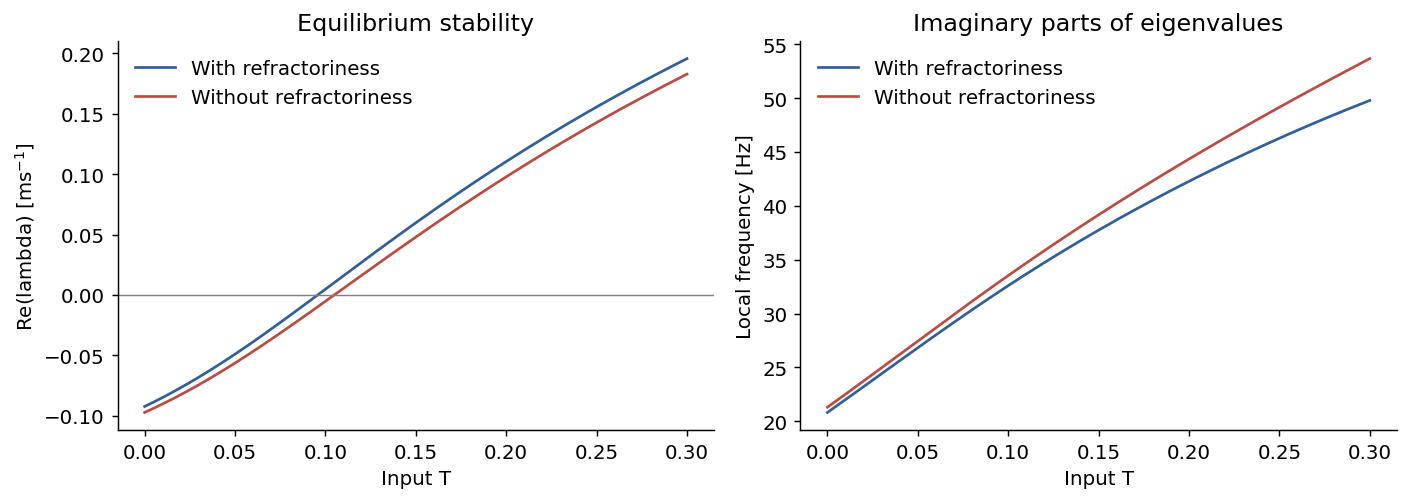

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for curve, color, label in zip(comparison_curves, ['#315f98', '#b94d43'], ['With refractoriness', 'Without refractoriness']):
    T_values = curve['T']
    eigenvalues = curve['eigenvalues']
    axes[0].plot(T_values, eigenvalues.real.max(axis=1), color=color, label=label)
    axes[1].plot(T_values, abs(eigenvalues.imag).max(axis=1)*1000/(2*np.pi), color=color, label=label)
axes[0].axhline(0, color='grey', lw=.8)
axes[0].set(xlabel='Input T', ylabel='Re(lambda) [ms$^{-1}$]', title='Equilibrium stability')
axes[1].set(xlabel='Input T', ylabel='Local frequency [Hz]', title='Imaginary parts of eigenvalues')
for axis in axes:
    axis.legend(frameon=False)
fig.tight_layout()
plt.show()


In [13]:
refractory_original = refractory.copy()
refractory[:] = 0.
T_without = brentq(trace_at, .04, .15, xtol=1e-13)
x_without = equilibrium(T_without)
J_hopf, B_hopf, C_hopf = derivatives(x_without, T_without)
values, vectors = np.linalg.eig(J_hopf)
index = np.argmax(values.imag)
omega = values[index].imag
q = vectors[:, index]
left_values, left_vectors = np.linalg.eig(J_hopf.T)
p = left_vectors[:, np.argmin(abs(left_values + 1j*omega))]
p = p / np.conj(np.vdot(p, q))
G21_without = np.vdot(p, Cform(q, q, q.conj())
    - 2*Bform(q, np.linalg.solve(J_hopf, Bform(q, q.conj())))
    + Bform(q.conj(), np.linalg.solve(2j*omega*np.eye(2)-J_hopf, Bform(q, q))))
l1_without = G21_without.real / (2*omega)
print('First Lyapunov coefficient without refractoriness:', l1_without)
refractory[:] = refractory_original
# Restore the original Hopf quantities for subsequent calculations.
J_hopf, B_hopf, C_hopf = derivatives(x_hopf, T_hopf)
values, vectors = np.linalg.eig(J_hopf)
index = np.argmax(values.imag)
omega = values[index].imag
q = vectors[:, index]
left_values, left_vectors = np.linalg.eig(J_hopf.T)
p = left_vectors[:, np.argmin(abs(left_values + 1j*omega))]
p = p / np.conj(np.vdot(p, q))


First Lyapunov coefficient without refractoriness: -2.6191187457442884


### Local eigenvalue frequencies

These frequencies are $1000|\operatorname{Im}\lambda|/(2\pi)$ at the respective equilibria. Above the Hopf threshold the equilibrium is unstable, so these are local spiral frequencies, not predictions of the final cycle period.

| Constant input T | With refractoriness (Hz) | Without refractoriness (Hz) |
|---:|---:|---:|
| 0.00 | 20.820 | 21.305 |
| 0.04 | 25.624 | 26.213 |
| 0.10 | 32.594 | 33.530 |
| 0.20 | 42.285 | 44.352 |
| 0.30 | 49.791 | 53.677 |

At the respective Hopf thresholds, onset frequencies are 32.127 Hz with refractoriness and 34.110 Hz without it.

In [14]:
for T in [0., .04, .1, .2, .3]:
    x = eq_cmp(T, False)
    v = W_cmp @ x + thalamic_cmp*T
    ge, gi = dp_cmp(v)
    trace_explicit = -4/15 + 42*ge - 18*gi
    det_explicit = (1 - 210*ge + 270*gi + 18900*ge*gi)/75
    J0 = jac_cmp(x, T, False)
    assert np.isclose(trace_explicit, np.trace(J0), rtol=1e-12, atol=1e-12)
    assert np.isclose(det_explicit, np.linalg.det(J0), rtol=1e-12, atol=1e-12)
    radical = np.sqrt(complex(trace_explicit**2-4*det_explicit))
    lambdas = np.array([(trace_explicit+radical)/2, (trace_explicit-radical)/2])
    print(f'T={T:.2f}: trace={trace_explicit:.8f}, det={det_explicit:.8f}, lambda={lambdas}')


T=0.00: trace=-0.19473920, det=0.02740018, lambda=[-0.0973696+0.13386313j -0.0973696-0.13386313j]
T=0.04: trace=-0.13134926, det=0.03143943, lambda=[-0.06567463+0.16470054j -0.06567463-0.16470054j]
T=0.10: trace=-0.01060879, det=0.04441142, lambda=[-0.00530439+0.2106734j -0.00530439-0.2106734j]
T=0.20: trace=0.19562699, det=0.08722568, lambda=[0.09781349+0.27867221j 0.09781349-0.27867221j]
T=0.30: trace=0.36574467, det=0.14718838, lambda=[0.18287234+0.33726265j 0.18287234-0.33726265j]


### Periodic orbits without refractoriness

**Removing refractoriness does not remove the Hopf.** It remains supercritical, at the higher threshold $T_H=0.1049526$. The onset frequency is 34.1104 Hz.

The calculation below checks the explicit eigenvalue formulas and refines the cycles with shooting. At $T=0.2$ and 0.3, their frequencies are about 19.05 and 20.31 Hz, versus 15.65 and 15.24 Hz with refractoriness.


In [15]:
refractory_saved = refractory.copy()
refractory[:] = 0.
# Numerical continuation of the attracting cycle, using the preceding orbit.
T_values = np.array([T_without+.0002, .106,.108,.11,.12,.13,.14,.15,.16,.18,.2,.25,.3])
cycles_no_ref = []
state = x_without + np.array([.03,0.])
for T in T_values:
    growth = max(np.linalg.eigvals(derivatives(equilibrium(T),T)[0]).real)
    settling = max(3500., 18/max(growth,1e-5))
    sol = solve_ivp(lambda t,x: field(x,T), (0,settling),state,rtol=2e-9,atol=1e-11)
    state = sol.y[:,-1]
    times = np.arange(0,2000.,.1)
    sol = solve_ivp(lambda t,x: field(x,T),(0,2000.),state,t_eval=times,rtol=2e-9,atol=1e-11)
    signal = sol.y[0]
    peaks,_ = find_peaks(signal,prominence=.1*np.ptp(signal))
    if len(peaks)<3:
        raise RuntimeError(f'No resolved cycle at T={T}')
    period = np.mean(np.diff(times[peaks]))
    start,stop = peaks[-2],peaks[-1]
    orbit_time = times[start:stop+1]-times[start]
    orbit = sol.y[:,start:stop+1]
    eig = np.linalg.eigvals(derivatives(equilibrium(T),T)[0])
    divergence = np.array([np.trace(derivatives(x,T)[0]) for x in orbit.T])
    floquet_log = np.trapz(divergence,orbit_time)
    cycles_no_ref.append(dict(T=float(T),period=float(period),frequency=1000/period,
        amplitude=float(np.ptp(signal)),minimum=float(signal.min()),maximum=float(signal.max()),
        eigen_frequency=float(max(abs(eig.imag))*1000/(2*np.pi)),
        floquet_log=float(floquet_log),time=orbit_time,orbit=orbit))
    state = sol.y[:,-1]
    print(f'T={T:.6f}: cycle={1000/period:.4f} Hz; peak-to-peak={np.ptp(signal):.5f}; log transverse multiplier={floquet_log:.5f}',flush=True)


# Shooting at a maximum of E fixes the arbitrary phase.
for c in cycles_no_ref:
    T=c['T']
    def residual(z):
        sol=solve_ivp(lambda t,x:field(x,T),(0,z[2]),z[:2],rtol=2e-10,atol=1e-12)
        return np.r_[sol.y[:,-1]-z[:2],field(z[:2],T)[0]]
    initial=np.r_[c['orbit'][:,0],c['period']]
    result=root(residual,initial,tol=1e-9)
    if np.max(abs(residual(result.x)))>1e-7 or result.x[2]<10:
        raise RuntimeError(f'Shooting failed at {T}')
    period=result.x[2]
    tt=np.linspace(0,period,1001)
    sol=solve_ivp(lambda t,x:field(x,T),(0,period),result.x[:2],t_eval=tt,rtol=2e-10,atol=1e-12)
    orbit=sol.y
    c.update(period=float(period),frequency=1000/period,amplitude=float(np.ptp(orbit[0])),minimum=float(orbit[0].min()),maximum=float(orbit[0].max()),time=tt,orbit=orbit,closure_error=float(np.max(abs(residual(result.x)[:2]))))
    c['floquet_log']=float(np.trapz([np.trace(derivatives(x,T)[0]) for x in orbit.T],tt))
    print(f"shooting T={T:.6f}: f={c['frequency']:.6f}, closure={c['closure_error']:.2g}, logmu={c['floquet_log']:.5f}",flush=True)
cycles_no_ref.sort(key=lambda c:c['T'])

refractory[:] = refractory_saved


In [16]:
print('T         f_cycle [Hz]   period [ms]    amplitude E    log(m_perp)   exponent [ms^-1]   closure')
for c in cycles_no_ref:
    print(f"{c['T']:.6f} {c['frequency']:12.6f} {c['period']:12.6f} {c['amplitude']:12.6f} {c['floquet_log']:13.6f} {c['floquet_log']/c['period']:18.7f} {c['closure_error']:.2g}")

T         f_cycle [Hz]   period [ms]    amplitude E    log(m_perp)   exponent [ms^-1]   closure
0.105153    34.088599    29.335321     0.048198     -0.012570         -0.0004285 8.9e-16
0.106000    33.996290    29.414974     0.110975     -0.065749         -0.0022352 4.3e-14
0.108000    33.777633    29.605390     0.192072     -0.190611         -0.0064384 3.3e-16
0.110000    33.558053    29.799107     0.250853     -0.314250         -0.0105456 7.2e-15
0.120000    32.451870    30.814865     0.466987     -0.901375         -0.0292513 6.2e-14
0.130000    31.334226    31.913984     0.651383     -1.409506         -0.0441658 7.1e-14
0.140000    30.182022    33.132307     0.836916     -1.816512         -0.0548260 8.2e-11
0.150000    28.933342    34.562202     1.040968     -2.114954         -0.0611927 8.4e-15
0.160000    27.459600    36.417137     1.290469     -2.298468         -0.0631150 9.5e-13
0.180000    21.746884    45.983600     2.531504     -2.389896         -0.0519728 8.4e-15
0.200000    19

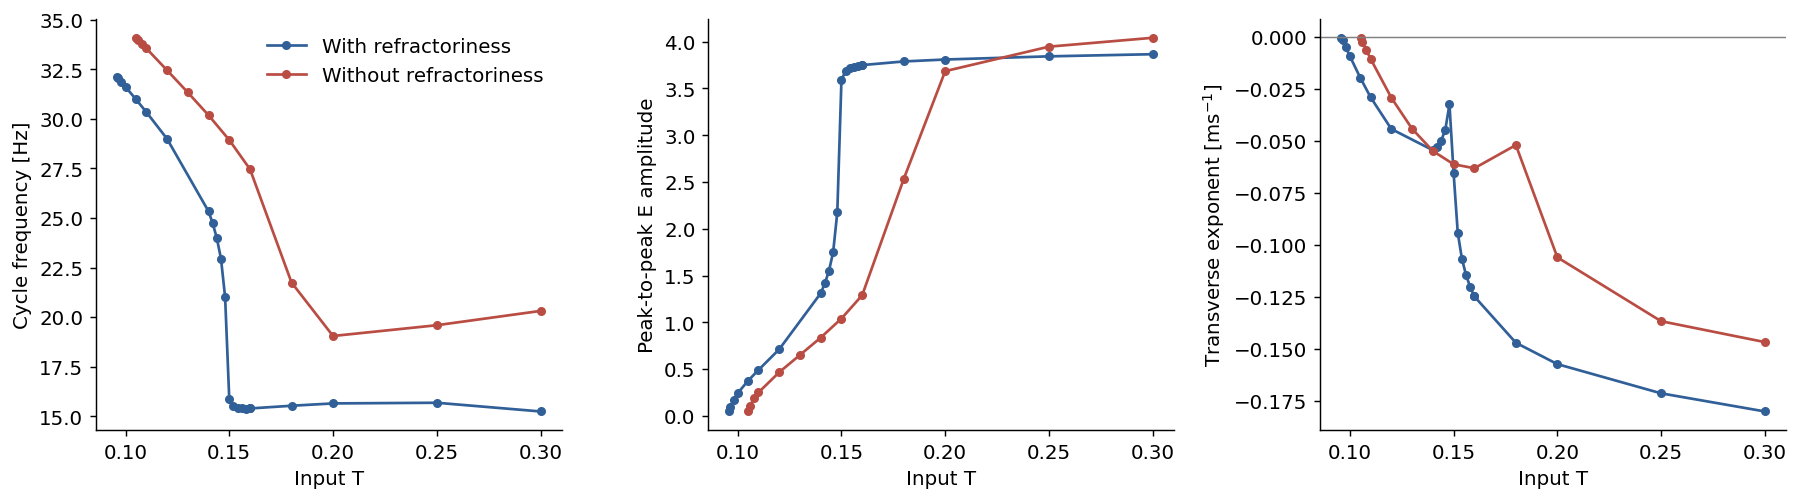

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for branch, color, label in [(cycles, '#315f98', 'With refractoriness'), (cycles_no_ref, '#b94d43', 'Without refractoriness')]:
    t = np.array([c['T'] for c in branch])
    axes[0].plot(t, [c['frequency'] for c in branch], 'o-', ms=4, color=color, label=label)
    axes[1].plot(t, [c['amplitude'] for c in branch], 'o-', ms=4, color=color)
    axes[2].plot(t, [c['floquet_log']/c['period'] for c in branch], 'o-', ms=4, color=color)
axes[0].set(xlabel='Input T', ylabel='Cycle frequency [Hz]')
axes[1].set(xlabel='Input T', ylabel='Peak-to-peak E amplitude')
axes[2].set(xlabel='Input T', ylabel='Transverse exponent [ms$^{-1}$]')
axes[2].axhline(0, color='grey', lw=.8)
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()


## 7. Reading a branch diagram

Here the horizontal axis is **input T, not time**. The black equilibrium curve is solid where stable and dashed where unstable. The coloured curves show minimum and maximum E of **the same cycle**, not two different cycles.

Following a branch means finding neighbouring solutions as T changes. The sampled cycles below are compatible with a branch growing from Hopf, but joining their extrema with lines does not prove that connection.


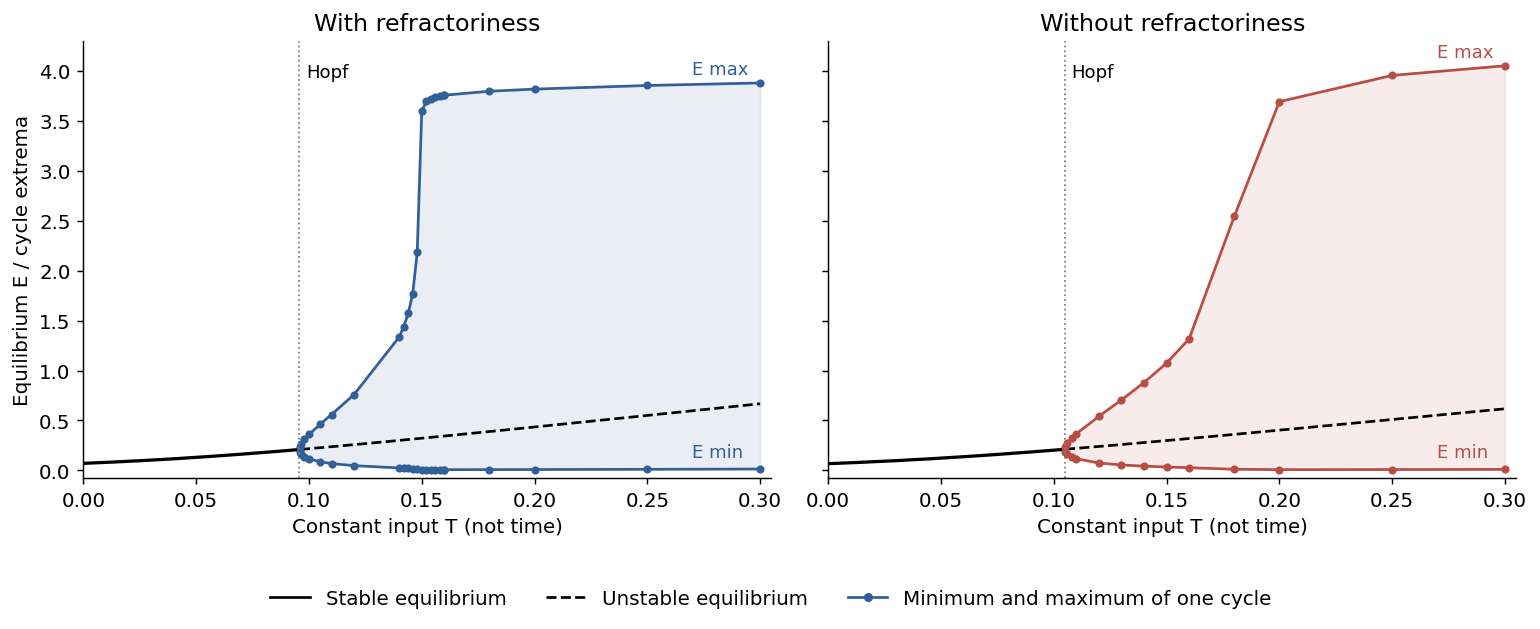

In [18]:
from matplotlib.lines import Line2D
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), sharey=True)
for axis, curve, branch, threshold, title, color in zip(
    axes, comparison_curves, [cycles, cycles_no_ref], [T_hopf, T_without],
    ['With refractoriness', 'Without refractoriness'], ['#315f98', '#b94d43']):
    t = curve['T']
    eq_E = curve['equilibria'][:, 0]
    stable = curve['eigenvalues'].real.max(axis=1) < 0
    axis.plot(t, np.where(stable, eq_E, np.nan), color='black', lw=1.8)
    axis.plot(t, np.where(~stable, eq_E, np.nan), '--', color='black', lw=1.5)
    branch_t = np.array([c['T'] for c in branch])
    minimum = np.array([c['minimum'] for c in branch])
    maximum = np.array([c['maximum'] for c in branch])
    axis.fill_between(branch_t, minimum, maximum, color=color, alpha=.10)
    axis.plot(branch_t, minimum, 'o-', color=color, ms=3.5)
    axis.plot(branch_t, maximum, 'o-', color=color, ms=3.5)
    axis.axvline(threshold, ls=':', color='grey', lw=1)
    axis.text(threshold+.003, 4.08, 'Hopf', fontsize=10, va='top')
    axis.text(.27, maximum[-1]+.09, 'E max', color=color, fontsize=10)
    axis.text(.27, minimum[-1]+.12, 'E min', color=color, fontsize=10)
    axis.set(xlabel='Constant input T (not time)', title=title, xlim=(0, .305), ylim=(-.08, 4.3))
axes[0].set_ylabel('Equilibrium E / cycle extrema')
handles=[Line2D([0],[0],color='black',label='Stable equilibrium'),
         Line2D([0],[0],color='black',ls='--',label='Unstable equilibrium'),
         Line2D([0],[0],color='#315f98',marker='o',ms=4,label='Minimum and maximum of one cycle')]
fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(.5,-.04))
fig.tight_layout(rect=(0,.07,1,1))
plt.show()


## 8. Transverse stability: Floquet multiplier and exponent

A perturbation along an autonomous cycle only changes its phase: its tangential multiplier is 1. A transverse perturbation moves away from the orbit. After one period,

$$
\delta_{n+1}\simeq m_\perp\delta_n,
\qquad
\lambda_\perp=\frac{\log|m_\perp|}{\mathcal T}.
$$

If $\lambda_\perp<0$, the cycle attracts nearby trajectories; if positive, it repels them. This is an average local rate with periodic modulation, not necessarily monotonic decay of Euclidean distance at every instant. It is neither an equilibrium eigenvalue nor the first Lyapunov coefficient of Hopf.

For a planar autonomous system,

$$
m_\perp=\exp\!\left(\int_0^{\mathcal T}\operatorname{tr}J(x(t))\,dt\right),
\qquad
\lambda_\perp=\frac{1}{\mathcal T}\int_0^{\mathcal T}\operatorname{tr}J(x(t))\,dt.
$$

An unstable equilibrium may lie inside a stable cycle: the point repels nearby trajectories while the orbit attracts transverse deviations.

In [19]:
for label, branch in [('With refractoriness', cycles), ('Without refractoriness', cycles_no_ref)]:
    cycle = min(branch, key=lambda c: abs(c['T']-.2))
    multiplier = np.exp(cycle['floquet_log'])
    exponent = cycle['floquet_log']/cycle['period']
    print(f"{label}, T=0.20: period={cycle['period']:.4f} ms; m_perp={multiplier:.6g}; lambda_perp={exponent:.6f} ms^-1")


With refractoriness, T=0.20: period=63.9024 ms; m_perp=4.3308e-05; lambda_perp=-0.157227 ms^-1
Without refractoriness, T=0.20: period=52.4941 ms; m_perp=0.00384598; lambda_perp=-0.105931 ms^-1


## Main conclusions

- **Is it Hopf? Yes.** Both cases have a transverse eigenvalue crossing and a negative first Lyapunov coefficient: a supercritical Hopf.
- **Do the equilibrium eigenvalues predict the 15 Hz cycle? No.** They describe small perturbations near the equilibrium. The large-cycle frequency comes from its full orbit.
- **Do oscillations persist without refractoriness? Yes.** Threshold and cycle frequencies change, but oscillations remain.
- **Is the global branch connection established? Not yet.** The sampled cycles support it; dedicated periodic-orbit continuation is needed to verify it.

Reference: Pinto et al. (1996), *A quantitative population model of whisker barrels: Re-examining the Wilson–Cowan equations*. [DOI](https://doi.org/10.1007/BF00161134).
